# Clean D_SEI Sweep

Run the full simulation (through formation aging, `include_flag=3`) **once** per grid point,
then post-process the voltage RMSE for three different time windows using the `phase` column:

| Window | Filter | Description |
|--------|--------|-------------|
| Formation cycling | `phase <= PHASE_FORMATION_CYCLING` | Through all formation cycles + final rest |
| All ~400 h | full DataFrame | Through formation aging |

Key differences from previous notebooks:
- **Consistent simulation data** across all three RMSE windows
- Uses `expt1` (cell 152064, base repeat 2) for baseline
- Always applies `y_range=(3.2, 4.2)` to exclude low-voltage rest/discharge data
- Fixed `rho` and `kappa` parameters throughout

In [26]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys, os
if os.path.basename(os.getcwd()) in ('notebooks', 'notebooks_2026'):
    os.chdir('../')
    sys.path.insert(0, 'src/')

import numpy as np
import matplotlib.pyplot as plt
import pickle

from src import simutils, ioutils
from src.simutils import (
    PHASE_PRE_FORMATION,
    PHASE_FIRST_CHARGE,
    PHASE_FORMATION_CYCLING,
    PHASE_RPT1,
    PHASE_FORMATION_AGING,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load experimental data

In [27]:
expt_base, _ = ioutils.fetch_experimental_data(152064, 600)   # Base1
expt_fast, _ = ioutils.fetch_experimental_data(152071, 600)   # Fast
expt_fp,   _ = ioutils.fetch_experimental_data(152098, 600)   # Fast+

print(f"Base1  : {len(expt_base['arbin_time'])} pts, "
      f"t_max = {expt_base['arbin_time'].max()/3600:.1f} h")
print(f"Fast   : {len(expt_fast['arbin_time'])} pts, "
      f"t_max = {expt_fast['arbin_time'].max()/3600:.1f} h")
print(f"Fast+  : {len(expt_fp['arbin_time'])} pts, "
      f"t_max = {expt_fp['arbin_time'].max()/3600:.1f} h")

Base1  : 86724 pts, t_max = 497.5 h
Fast   : 67790 pts, t_max = 497.5 h
Fast+  : 65341 pts, t_max = 497.5 h


In [28]:
# Smooth the early-time kink artefact in expansion data
kink_regions = [
    (expt_base, 'base', 0.5, 0.85),
    (expt_fast, 'fast', 0.5, 0.6),
    (expt_fp,   'fp',   0.5, 0.55),
]
for expt, label, t_start, t_end in kink_regions:
    daq_time = np.array(expt['daq_time'])
    daq_strain = np.array(expt['daq_strain'])
    daq_time_hours = (daq_time - daq_time[0]) / 3600.0
    expt['daq_strain_smoothed'] = ioutils.smooth_kink_region(
        daq_time_hours, daq_strain, t_start, t_end
    )
    print(f"{label}: smoothed kink region [{t_start}, {t_end}] h")

base: smoothed kink region [0.5, 0.85] h
fast: smoothed kink region [0.5, 0.6] h
fp: smoothed kink region [0.5, 0.55] h


## Sweep parameters

In [29]:
nn = 35

diff_ec_vec = np.logspace(-20, -16, nn)
diff_vc_vec = np.logspace(-21, -12, nn + 1)

# Fixed SEI density and conductivity parameters
rho_ec_opt = 1.29
rho_vc_opt = 1.49
kappa_ec_opt = 0.090e-3
kappa_vc_opt = 0.051e-3

# Three time windows for RMSE computation
WINDOWS = {
    'fc':   PHASE_FIRST_CHARGE,       # first charge only
    'form': PHASE_FORMATION_CYCLING,   # all formation cycling
    'all':  PHASE_FORMATION_AGING,     # full ~400 h
}

# RMSE matrices: {window}_{protocol} for voltage, {window}_{protocol}_e for expansion
shape = (len(diff_ec_vec), len(diff_vc_vec))
rmse = {}
for w in WINDOWS:
    for p in ('base', 'fast', 'fp'):
        rmse[f'{w}_{p}'] = np.full(shape, np.nan)
        rmse[f'{w}_{p}_e'] = np.full(shape, np.nan)

print(f"Grid: {nn} x {nn+1} = {nn*(nn+1)} points per protocol")
print(f"Total simulations: {nn*(nn+1)*3}")

Grid: 35 x 36 = 1260 points per protocol
Total simulations: 3780


## Run the sweep

Each simulation runs `include_flag=3` (full protocol through formation aging).
The three voltage RMSE windows are computed in post-processing from the same simulation data.

In [30]:
sim_kwargs = dict(
    rho_ec=rho_ec_opt, rho_vc=rho_vc_opt,
    kappa_ec=kappa_ec_opt, kappa_vc=kappa_vc_opt,
    dt=1, include_flag=3,
)

protocols = [
    ('base',  'base',  expt_base),
    ('fast',  'fast',  expt_fast),
    ('fast+', 'fp',    expt_fp),
]

count = 0
total = nn * (nn + 1)

for i, diff_ec in enumerate(diff_ec_vec):
    for j, diff_vc in enumerate(diff_vc_vec):

        count += 1
        print(f'\r[{count}/{total}] D_EC={diff_ec:.2e}  D_VC={diff_vc:.2e}', end='')

        for formation_type, key, expt in protocols:
            try:
                df = simutils.run_sim(formation_type, diff_ec, diff_vc, **sim_kwargs)
            except Exception:
                continue

            t_expt = expt['arbin_time']
            v_expt = expt['arbin_voltage']
            t_expt_daq = expt['daq_time']
            e_expt = expt['daq_strain_smoothed']

            for w_name, phase_max in WINDOWS.items():
                mask = df['phase'] <= phase_max
                rmse_v, _, _ = simutils.calculate_rmse(
                    t_expt, v_expt,
                    df['t'][mask].values, df['vt'][mask].values,
                    y_range=(3.2, 4.2),
                    ignore_time_range=(0, 30 * 60),
                )
                rmse[f'{w_name}_{key}'][i, j] = rmse_v

                rmse_e, _, _ = simutils.calculate_rmse(
                    t_expt_daq, e_expt,
                    df['t'][mask].values, df['expansion'][mask].values * 1e6,
                    ignore_time_range=(0, 30 * 60),
                )
                rmse[f'{w_name}_{key}_e'][i, j] = rmse_e

print('\nDone.')

[1260/1260] D_EC=1.00e-16  D_VC=1.00e-12
Done.


## Save results

In [31]:
results = {
    'diff_ec_vec': diff_ec_vec,
    'diff_vc_vec': diff_vc_vec,
    'rho_ec': rho_ec_opt,
    'rho_vc': rho_vc_opt,
    'kappa_ec': kappa_ec_opt,
    'kappa_vc': kappa_vc_opt,
    **rmse,
}

pkl_path = 'notebooks_2026/data/simulation_results_clean_dsei_sweep_20260422.pkl'
with open(pkl_path, 'wb') as f:
    pickle.dump(results, f)
print(f'Saved to {pkl_path}')

Saved to outputs/simulation_results_clean_dsei_sweep_20260422.pkl


## Plot heatmaps

Compare the voltage RMSE maps across the three time windows (rows) and three formation protocols (columns).

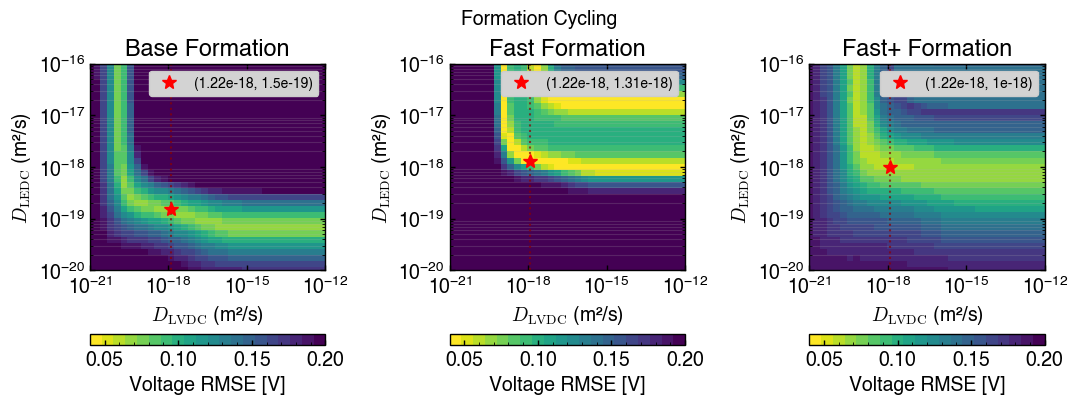

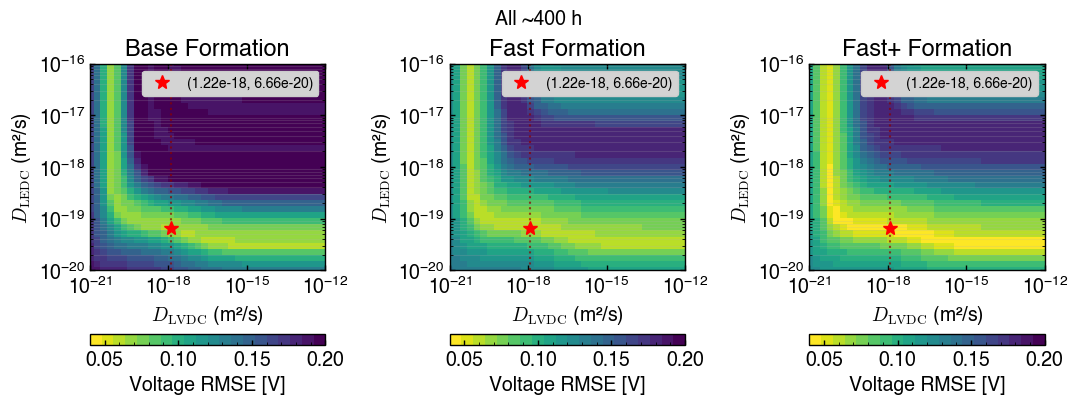

In [46]:
# Reload from pickle (so this cell can be re-run independently)
with open('notebooks_2026/data/simulation_results_clean_dsei_sweep_20260422.pkl', 'rb') as f:
    res = pickle.load(f)

diff_ec_vec = res['diff_ec_vec']
diff_vc_vec = res['diff_vc_vec']

window_configs = {
    'form': ('Formation Cycling',  True, 'vertical', 1.22e-18),
    'all':  ('All ~400 h',         True, 'vertical', 1.22e-18)
}

for w_key, (w_label, tf, orient, coord) in window_configs.items():

    simutils.plot_heatmaps_diff(
        diff_ec_vec, diff_vc_vec,
        res[f'{w_key}_base'], res[f'{w_key}_fast'], res[f'{w_key}_fp'],
        'Voltage RMSE [V]',
        to_annotate=tf,
        annotation_orientation=orient,
        annotation_coord=coord,
        tosave=True,
        zmin=0.04, zmax=0.2,
        savename=f'outputs/figures/heatmap_clean_dsei_{w_key}.svg',
    )
    plt.suptitle(w_label, fontsize=14, y=1.02)
    plt.show()

## Expansion RMSE heatmaps

Same sweep results, but comparing simulated expansion (strain × 1e6) against
smoothed experimental expansion curves.  Uses the same per-window / per-protocol
layout as the voltage RMSE plots above.

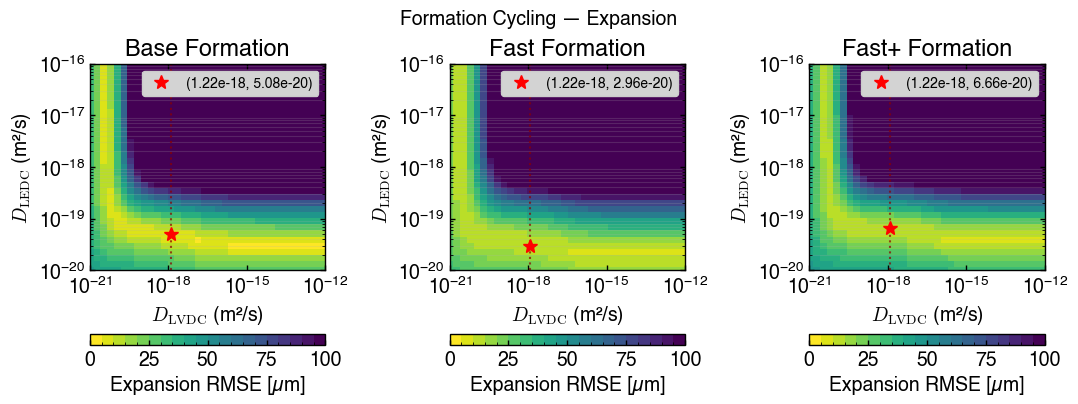

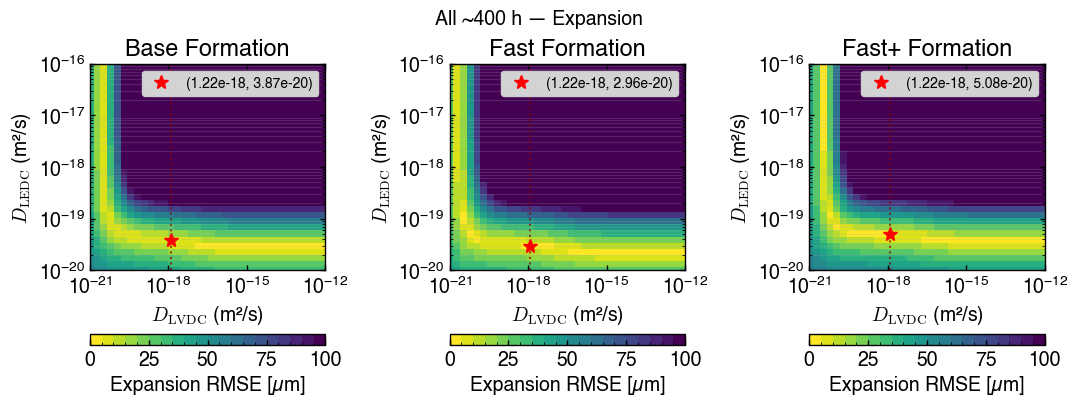

In [44]:
# Reload from pickle (so this cell can be re-run independently)
with open('notebooks_2026/data/simulation_results_clean_dsei_sweep_20260422.pkl', 'rb') as f:
    res = pickle.load(f)

diff_ec_vec = res['diff_ec_vec']
diff_vc_vec = res['diff_vc_vec']

window_configs_e = {
    'form': ('Formation Cycling',  True, 'vertical', 1.22e-18),
    'all':  ('All ~400 h',         True, 'vertical', 1.22e-18)
}

for w_key, (w_label, tf, orient, coord) in window_configs_e.items():

    simutils.plot_heatmaps_diff(
        diff_ec_vec, diff_vc_vec,
        res[f'{w_key}_base_e'], res[f'{w_key}_fast_e'], res[f'{w_key}_fp_e'],
        'Expansion RMSE [µm]',
        to_annotate=tf,
        annotation_orientation=orient,
        annotation_coord=coord,
        annotation_line_only=False,
        tosave=True,
        zmin=0, zmax=100,
        savename=f'outputs/figures/heatmap_clean_dsei_{w_key}_expansion.svg',
    )
    plt.suptitle(f'{w_label} — Expansion', fontsize=14, y=1.02)
    plt.show()